Task 2.2

In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
# 1) Детектор и затухание фотонов
class Detector:
    def __init__(self, R=2.0, N=40, r=0.1, a=0.5, lambda_zat=8.0):
        self.R = R
        self.N = N
        self.r = r
        self.a = a
        self.lambda_zat = lambda_zat
        self.fmt_positions = self.generate_fmts()

    def generate_fmts(self):
        phi = np.random.uniform(0, 2 * np.pi, self.N)
        U = np.random.uniform(-1, 1, self.N)
        sin_theta = np.sqrt(1 - U**2)

        x = self.R * sin_theta * np.cos(phi)
        y = self.R * sin_theta * np.sin(phi)
        z = self.R * U

        return np.column_stack([x, y, z])

    def count_hits(self, pos, directions, zatuhanie=True):
        b = directions @ pos
        c = np.dot(pos, pos) - self.R**2
        L = -b + np.sqrt(b**2 - c)
        points = pos + L[:, None] * directions

        # расстояния от точек на сфере до ФЭУ
        d_sq = 2 * self.R**2 - 2 * (points @ self.fmt_positions.T)
        mask = np.min(d_sq, axis=1) <= self.r**2

        if not zatuhanie:
            return int(np.sum(mask))

        p = np.exp(-L[mask] / self.lambda_zat)
        return int(np.sum(np.random.random(len(p)) < p))

In [3]:
# 2) Источник и направления фотонов
class Source:
    def __init__(self, Y=10000, pos=(0.0, 0.0, 0.0)):
        self.Y = Y
        self.pos = np.array(pos, dtype=float)

    def generate_directions(self, E):
        N = int(self.Y * E)
        phi = np.random.uniform(0, 2 * np.pi, N)
        U = np.random.uniform(-1, 1, N)
        sin_theta = np.sqrt(1 - U**2)

        x = sin_theta * np.cos(phi)
        y = sin_theta * np.sin(phi)
        z = U

        return np.column_stack([x, y, z])

In [4]:
# 3) Моделирование одного события
def simulate_event(det, source, E, zatuhanie=True):
    directions = source.generate_directions(E)
    N_hit = det.count_hits(source.pos, directions, zatuhanie=zatuhanie)
    Q = np.random.poisson(N_hit * det.a)
    return Q

In [5]:
# 4) Параметры
R = 2.0
N = 40
r = 0.1
a = 0.5
Y = 10000
E = 1.0
lambda_zat = 8.0
N_events = 1000
z_vals = np.array([0.0, 0.5, 1.0, 1.5])

det = Detector(R, N, r, a, lambda_zat)

In [6]:
# 5) Моделирование с затуханием и без него
Q_no = np.zeros((len(z_vals), N_events), dtype=int)
Q_zat = np.zeros((len(z_vals), N_events), dtype=int)

for j, z in enumerate(z_vals):
    source = Source(Y, pos=(0.0, 0.0, z))

    for i in range(N_events):
        Q_no[j, i] = simulate_event(det, source, E, zatuhanie=False)
        Q_zat[j, i] = simulate_event(det, source, E, zatuhanie=True)

In [7]:
# 6) Средний заряд и ширина распределений
Q_mean_no = np.mean(Q_no, axis=1)
Q_mean_zat = np.mean(Q_zat, axis=1)
Q_std_no = np.std(Q_no, axis=1)
Q_std_zat = np.std(Q_zat, axis=1)

for j, z in enumerate(z_vals):
    delta_Q = (Q_mean_zat[j] - Q_mean_no[j]) / Q_mean_no[j] * 100
    print(f"z = {z:.1f} м")
    print(f"Без затухания: <Q> = {Q_mean_no[j]:.2f}, sigma_Q = {Q_std_no[j]:.2f}")
    print(f"С затуханием: <Q> = {Q_mean_zat[j]:.2f}, sigma_Q = {Q_std_zat[j]:.2f}")
    print(f"Изменение среднего заряда: {delta_Q:.2f}%\n")

z = 0.0 м
Без затухания: <Q> = 122.44, sigma_Q = 13.41
С затуханием: <Q> = 95.76, sigma_Q = 12.25
Изменение среднего заряда: -21.79%

z = 0.5 м
Без затухания: <Q> = 129.61, sigma_Q = 14.49
С затуханием: <Q> = 101.74, sigma_Q = 12.17
Изменение среднего заряда: -21.50%

z = 1.0 м
Без затухания: <Q> = 139.80, sigma_Q = 14.44
С затуханием: <Q> = 112.68, sigma_Q = 12.34
Изменение среднего заряда: -19.40%

z = 1.5 м
Без затухания: <Q> = 163.09, sigma_Q = 15.28
С затуханием: <Q> = 138.98, sigma_Q = 14.44
Изменение среднего заряда: -14.79%



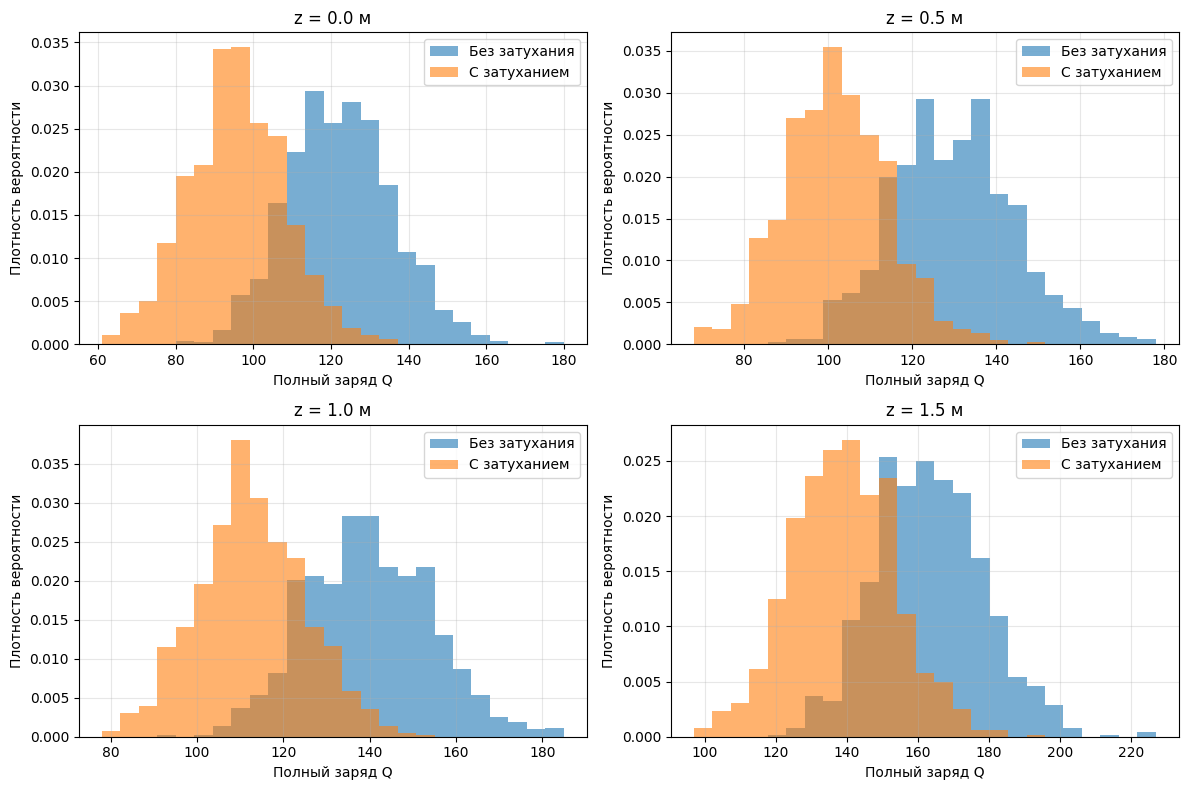

In [8]:
# 7) Распределения заряда при разных положениях источника
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for j, ax in enumerate(axes.flat):
    bins = np.histogram_bin_edges(np.concatenate([Q_no[j], Q_zat[j]]), bins=25)
    ax.hist(Q_no[j], bins=bins, density=True, alpha=0.6, label='Без затухания')
    ax.hist(Q_zat[j], bins=bins, density=True, alpha=0.6, label='С затуханием')
    ax.set_title(f'z = {z_vals[j]:.1f} м')
    ax.set_xlabel('Полный заряд Q')
    ax.set_ylabel('Плотность вероятности')
    ax.legend()
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

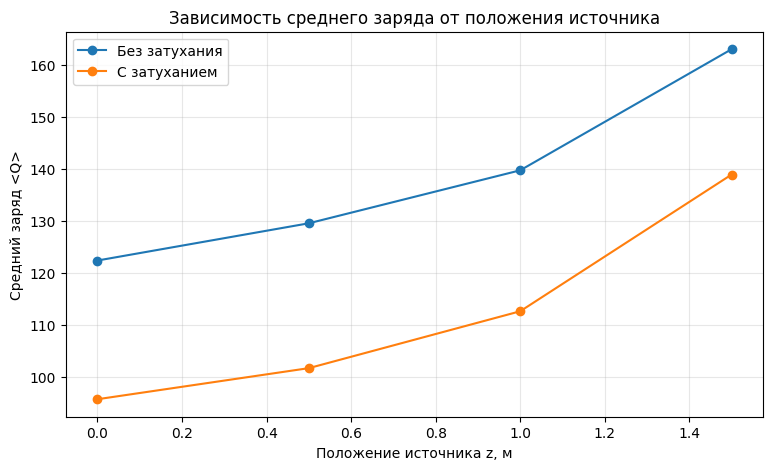

In [9]:
# 8) Зависимость среднего заряда от положения источника
plt.figure(figsize=(9, 5))
plt.plot(z_vals, Q_mean_no, 'o-', label='Без затухания')
plt.plot(z_vals, Q_mean_zat, 'o-', label='С затуханием')
plt.xlabel('Положение источника z, м')
plt.ylabel('Средний заряд <Q>')
plt.title('Зависимость среднего заряда от положения источника')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()